In [1]:
%pip install tensorboard

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import os
from torch.utils.data import DataLoader, TensorDataset, random_split
from torch.utils.tensorboard import SummaryWriter

In [3]:
cwd = os.getcwd()
num_csvs = len(os.listdir("C:\\Users\\seanf\\OneDrive\\Documents\\Master's Files\\2nd Year\\Eclipsing Binaries\\Data\\ELISa lightcurve data"))
fluxes_array = np.empty((0, 100))  # initialize fluxes_array to empty, will be replaced with first light curve

all_labels = np.loadtxt(os.path.join(cwd, "Data", "ELISa lightcurve data", "_labels.csv"), delimiter=',', usecols=0)
labels = np.array([]) 

# looping through each light curve csv file, adding them all to one 2d array of dimensions (num_csvs x 100)
for i in range(1, 3*num_csvs): # using 3 * num_csvs as csvs (currently) go from 1-999, many are missing, so this ensures we get all files 
    data_path = os.path.join(cwd, "Data", "ELISa lightcurve data", f"{i} lightcurve.csv")
    if os.path.exists(data_path): # only loads file if a lightcurve with that number exists, otherwise skips to next iteration
        data = np.loadtxt(data_path, delimiter=',', skiprows=1)
        phases = data[:, 0]
        fluxes = data[:, 1]
        label = all_labels[i]  # get the corresponding label for the light curve. 
        labels = np.append(labels, label)

        if fluxes_array.size < 1: # set up array withe the first light curve. Will only trigger on first iteration due to np.empty
            fluxes_array = fluxes
        else: # add the next light curve to a 2d array of light curves
            fluxes_array = np.vstack((fluxes_array, fluxes))

    else:
        continue


In [4]:
# sanity check cell

print(fluxes_array.shape)
print(num_csvs) # num_csvs should be one more, due to the labels file
print(labels.shape) 

print(all_labels[49])

(517, 100)
518
(517,)
1.0


In [5]:
# Check for available devices and select if available
if torch.cuda.is_available():
    device = torch.device("cuda")       #CUDA GPU
else:
    device = torch.device("cpu")        #if nothing is found use the CPU
print(f"Using device: {device}")

Using device: cpu


In [6]:
fluxes_norm = (fluxes_array - fluxes_array.mean(axis=1, keepdims=True)) / fluxes_array.std(axis=1, keepdims=True)

light_curves_tensor = torch.tensor(fluxes_norm, dtype=torch.float32)
light_curve_labels = torch.tensor(labels, dtype=torch.long)

In [7]:
# Splitting synthetic data into training and validation sets
train_size = round(0.8 * fluxes_array.shape[0]) # round used to avoid rounding errors with int() function that only rounds down
val_size = round(0.2 * fluxes_array.shape[0])


train_dataset, val_dataset = random_split(TensorDataset(light_curves_tensor, light_curve_labels), [train_size, val_size])

# Loading training and validation data into DataLoader for batching
batch_size = 10
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

writer = SummaryWriter()  # Initialize TensorBoard writer

In [8]:
# ResNet 50: 
# conv1: 7x7, 64, stride 2. output size 112 x 112
# here the 64 means that the output of this layer will have 64 channels, and the 112 means that the output will have a height and width of 112 pixels.
# conv2_x: 3 x [1x1, 64; 3x3, 64; 1x1, 256], output size 56 x 56
# conv3_x: 4 x [1x1, 128; 3x3, 128; 1x1, 512], output size 28 x 28
# conv4_x: 6 x [1x1, 256; 3x3, 256; 1x1, 1024], output size 14 x 14
# conv5_x: 3 x [1x1, 512; 3x3, 512; 1x1, 2048], output size 7 x 7
# final layer (fully connected): 1x1, 2048, output size 1 x 1

# BUT! our model will be using raw data, not images of the plotted data. Our raw data has length of 100 data points.
# This means we will use 1D convolutional layers instead of 2D convolutional layers.
# So, the architecture will instead be:

# conv1: 7x1, 64, stride 2. output size 50 x 1
# The first 64 here means that the output of this layer will have 64 channels, and the 50 means that the output will have a length of 50 data points.
# 7 is used here as
# conv2_x: 3 x [1x1, 64; 3x1, 64; 1x1, 256], output size 25 x 1
# conv3_x: 4 x [1x1, 128; 3x1, 128; 1x1, 512], output size 13 x 1
# conv4_x: 6 x [1x1, 256; 3x1, 256; 1x1, 1024], output size 7 x 1
# conv5_x: 3 x [1x1, 512; 3x1, 512; 1x1, 2048], output size 4 x 1
# final layer (fully connected): 1x1, 2048, output size 1 x 1

In [9]:
num_classes = 2 # number of things we are trying to predict.
# in this case, we are trying to classify the eclipsing binary as detached or overcontact, so we have 2 classes.

# simplified cnn, not resnet:

def length(length, kernel_size, stride):
    return ((length - kernel_size) // stride) + 1

class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()

        self.conv1 = nn.Conv1d(in_channels=1, out_channels=64, kernel_size=2, stride=2,padding=2)
        self.pool = nn.AvgPool1d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv1d(in_channels=64, out_channels=128, kernel_size=2, stride=2)
        self.conv3 = nn.Conv1d(in_channels=128, out_channels=256, kernel_size=2, stride=2)
        self.fc1 = nn.Linear(256 * 3, num_classes) 

# cnn conv layer length formula: ((length - kernel_size) / stride){rounded down} + 1
# size: (batch_size, channels, length)



    def forward(self, x): # input size: (batch_size, 100)
        x = x.unsqueeze(1)          # (batch_size, 1, 100)
        x = F.relu(self.conv1(x))   # (batch_size, 64, 50)
        x = self.pool(x)            # (batch_size, 64, 25)
        x = F.relu(self.conv2(x))   # (batch_size, 128, 12)
        x = self.pool(x)            # (batch_size, 128, 6)
        x = F.relu(self.conv3(x))   # (batch_size, 256, 3)
        x = x.reshape(x.size(0), -1) # Flatten the tensor to (batch_size, 256 * 3) 
        x = self.fc1(x)
        
        return x

In [26]:
# hyperparameters!

lr = 0.001
epochs = 48
batch_size = 10

In [27]:
model = CNN().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=lr)
criterion = nn.CrossEntropyLoss()

In [ ]:
train_losses, val_losses = [], []

for epoch in range(epochs):
    model.train()
    train_loss=0
    for inputs, batch_labels in train_loader:
        inputs = inputs.to(device)  # Move inputs to the same device as the model
        batch_labels = batch_labels.to(device)
        optimizer.zero_grad() # set gradients to zero
        predictions = model(inputs) # forward pass
        loss = criterion(predictions, batch_labels) # calculate loss based on predictions and true labels
        loss.backward() # backpropagation
        optimizer.step() # update weights
        train_loss += loss.item() # accumulate loss for the epoch
    train_losses.append(train_loss / len(train_loader))

    writer.add_scalar('Training Loss', train_losses[-1], epoch)

# Validation
    model.eval()
    val_loss=0
    with torch.no_grad(): # make sure the gradients changed in this step
        for inputs, batch_labels in val_loader:
            inputs = inputs.to(device)  # Move inputs to the same device as the model
            batch_labels = batch_labels.to(device)
            predictions = model(inputs)
            loss = criterion(predictions, batch_labels)
            val_loss += loss.item()
    val_losses.append(val_loss / len(val_loader))

    writer.add_scalar('Validation Loss', val_losses[-1], epoch)


    print(f"Epoch {epoch}: Training Loss: {train_losses[-1]:.4f}, Validation Loss: {val_losses[-1]:.4f}")

# 21.6 seconds for 48 epochs => 0.45 seconds per epoch 

Epoch 0: Training Loss: 0.3588, Validation Loss: 0.1611
Epoch 1: Training Loss: 0.1514, Validation Loss: 0.0436
Epoch 2: Training Loss: 0.1136, Validation Loss: 0.0359
Epoch 3: Training Loss: 0.1114, Validation Loss: 0.0325
Epoch 4: Training Loss: 0.1003, Validation Loss: 0.0237
Epoch 5: Training Loss: 0.0843, Validation Loss: 0.0263
Epoch 6: Training Loss: 0.0827, Validation Loss: 0.0229
Epoch 7: Training Loss: 0.0833, Validation Loss: 0.0905
Epoch 8: Training Loss: 0.0846, Validation Loss: 0.0146
Epoch 9: Training Loss: 0.0968, Validation Loss: 0.0193
Epoch 10: Training Loss: 0.0770, Validation Loss: 0.0377
Epoch 11: Training Loss: 0.0596, Validation Loss: 0.0122
Epoch 12: Training Loss: 0.0558, Validation Loss: 0.0193
Epoch 13: Training Loss: 0.0568, Validation Loss: 0.0687
Epoch 14: Training Loss: 0.0767, Validation Loss: 0.0358
Epoch 15: Training Loss: 0.0629, Validation Loss: 0.0163
Epoch 16: Training Loss: 0.0571, Validation Loss: 0.0149
Epoch 17: Training Loss: 0.0542, Validati

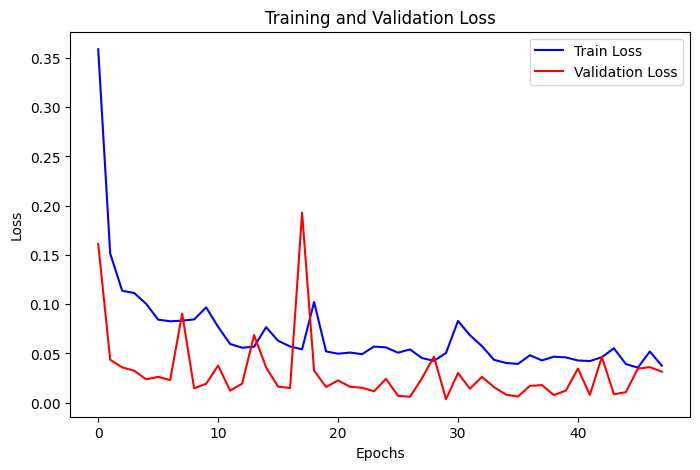

In [29]:
# Plot training/validation loss
plt.figure(figsize=(8, 5))
plt.plot(train_losses, label="Train Loss", color="blue")
plt.plot(val_losses, label="Validation Loss", color="red")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()